In [57]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import json

In [58]:
df=pd.read_csv(r"C:\Users\DELL\Downloads\Personal\Companies\Resume_prep\MMM\trucker_fintech_mmm_dataset.csv")

In [59]:
df.head(5)

,week_start,new_card_signups,avg_90d_retention_rate,billboard_spend,radio_spend,digital_spend,referral_budget_spend,diesel_price_usd,freight_volume_index
0,2023-01-01,350,0.663,16030.10,11238.12,8412.93,966.28,4.25,105.36
1,2023-01-08,368,0.681,22705.46,0.00,7436.28,2013.69,3.94,109.36
2,2023-01-15,398,0.680,16141.78,0.00,7177.78,1464.27,4.33,122.45
3,2023-01-22,410,0.695,17271.13,0.00,8243.69,2509.59,4.78,103.55
4,2023-01-29,475,0.681,16908.00,11220.26,8244.97,2416.31,3.90,102.58


In [60]:
CHANNELS = ["billboard_spend", "radio_spend", "digital_spend", "referral_budget_spend"]


In [61]:
CHANNELS

['billboard_spend', 'radio_spend', 'digital_spend', 'referral_budget_spend']

<Axes: xlabel='week_start'>

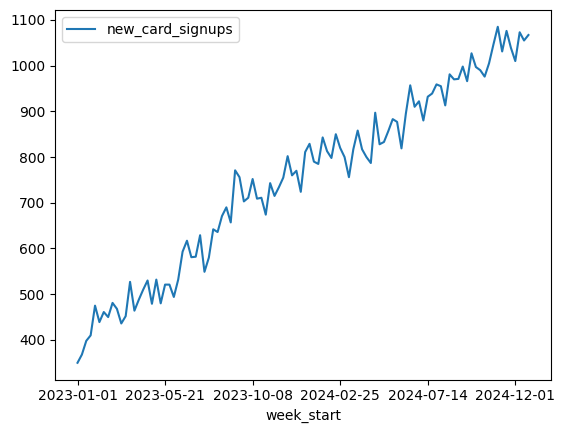

In [62]:
df.plot(x="week_start",y="new_card_signups")

<Axes: title={'center': 'Spend by Channel'}, xlabel='week_start'>

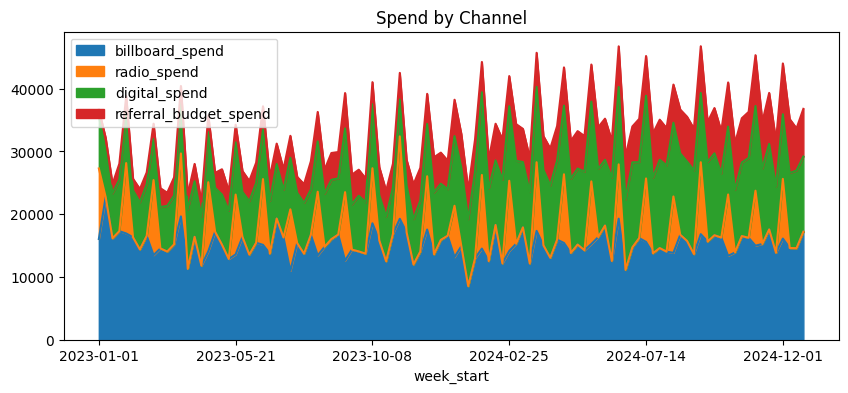

In [63]:
df.plot.area(x="week_start", y=CHANNELS, title="Spend by Channel", figsize=(10, 4))


In [64]:
total_spend=df[CHANNELS].sum()

In [65]:
total_spend

billboard_spend          1573395.74
radio_spend               266974.69
digital_spend            1046557.74
referral_budget_spend     509413.68
dtype: float64

<Axes: >

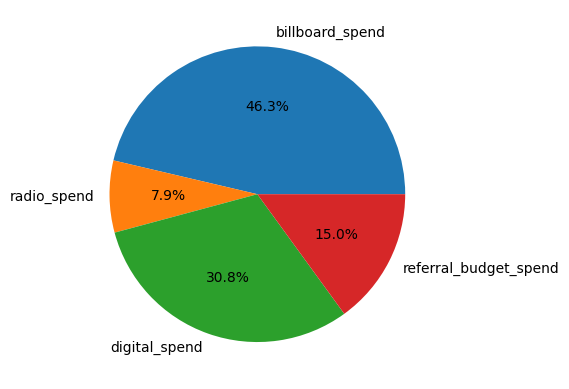

In [66]:
total_spend.plot.pie(autopct="%1.1f%%")

In [67]:
df_corr=df.drop(columns=["week_start","new_card_signups"])

In [68]:
df_corr

,avg_90d_retention_rate,billboard_spend,radio_spend,digital_spend,referral_budget_spend,diesel_price_usd,freight_volume_index
0,0.663,16030.10,11238.12,8412.93,966.28,4.25,105.36
1,0.681,22705.46,0.00,7436.28,2013.69,3.94,109.36
2,0.680,16141.78,0.00,7177.78,1464.27,4.33,122.45
3,0.695,17271.13,0.00,8243.69,2509.59,4.78,103.55
4,0.681,16908.00,11220.26,8244.97,2416.31,3.90,102.58
...,...,...,...,...,...,...,...
99,0.764,13816.86,0.00,10619.90,7202.14,4.36,123.82
100,0.742,16094.19,9517.92,10296.62,8090.14,3.78,98.57
101,0.772,14595.61,0.00,11944.45,8604.28,4.28,101.85
102,0.750,14564.64,0.00,12384.07,6705.93,4.32,115.10


<Axes: >

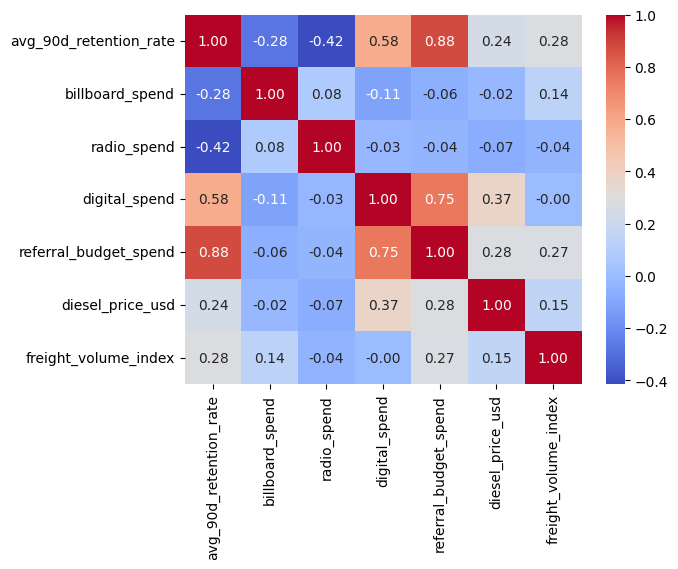

In [69]:
sns.heatmap(df_corr.corr(), annot=True, cmap="coolwarm", fmt=".2f")

In [70]:
total_budget = total_spend.sum()

In [71]:
total_budget

3396341.85

In [72]:
total_signups=df["new_card_signups"].sum()

In [73]:
total_signups

78076

In [74]:
CHANNELS

['billboard_spend', 'radio_spend', 'digital_spend', 'referral_budget_spend']

In [75]:
total_ads_spend=df[CHANNELS].sum()

In [76]:
total_ads_spend

billboard_spend          1573395.74
radio_spend               266974.69
digital_spend            1046557.74
referral_budget_spend     509413.68
dtype: float64

In [77]:
total_ads_spend=df["billboard_spend"].sum()+df["radio_spend"].sum()+df["digital_spend"].sum()+df["referral_budget_spend"].sum()

In [78]:
total_ads_spend

3396341.85

In [79]:
CAC=total_ads_spend/total_signups

In [80]:
CAC

43.500459167990165

In [81]:
# getting the decay rates by using Bayessaian model


In [82]:
import statsmodels.api as sm
import optuna
import warnings
warnings.filterwarnings("ignore")

In [83]:
def apply_adstock(spend, decay):
    res=np.zeros(len(spend))
    res[0]=spend[0]
    for i in range(1, len(df)):
        res[i]=spend[i]+(decay*spend[i-1])
    return res

    

In [84]:
#load the data
df=pd.read_csv(r"C:\Users\DELL\Downloads\Personal\Companies\Resume_prep\MMM\trucker_fintech_mmm_dataset.csv")
y=df["new_card_signups"].astype(float)

In [85]:
df

,week_start,new_card_signups,avg_90d_retention_rate,billboard_spend,radio_spend,digital_spend,referral_budget_spend,diesel_price_usd,freight_volume_index
0,2023-01-01,350,0.663,16030.10,11238.12,8412.93,966.28,4.25,105.36
1,2023-01-08,368,0.681,22705.46,0.00,7436.28,2013.69,3.94,109.36
2,2023-01-15,398,0.680,16141.78,0.00,7177.78,1464.27,4.33,122.45
3,2023-01-22,410,0.695,17271.13,0.00,8243.69,2509.59,4.78,103.55
4,2023-01-29,475,0.681,16908.00,11220.26,8244.97,2416.31,3.90,102.58
...,...,...,...,...,...,...,...,...,...
99,2024-11-24,1039,0.764,13816.86,0.00,10619.90,7202.14,4.36,123.82
100,2024-12-01,1010,0.742,16094.19,9517.92,10296.62,8090.14,3.78,98.57
101,2024-12-08,1073,0.772,14595.61,0.00,11944.45,8604.28,4.28,101.85
102,2024-12-15,1055,0.750,14564.64,0.00,12384.07,6705.93,4.32,115.10


In [86]:
y

0       350.0
1       368.0
2       398.0
3       410.0
4       475.0
        ...  
99     1039.0
100    1010.0
101    1073.0
102    1055.0
103    1067.0
Name: new_card_signups, Length: 104, dtype: float64

In [87]:
# make the data
weeks = pd.to_datetime(df["week_start"]).dt.isocalendar().week

In [88]:
weeks

0      52
1       1
2       2
3       3
4       4
       ..
99     47
100    48
101    49
102    50
103    51
Name: week, Length: 104, dtype: UInt32

In [89]:
df["time_trend"] = np.arange(len(df))
df["season_sin"] = np.sin(2 * np.pi * weeks / 52)
df["season_cos"] = np.cos(2 * np.pi * weeks / 52)


In [90]:
df.head(5)

,week_start,new_card_signups,avg_90d_retention_rate,billboard_spend,radio_spend,digital_spend,referral_budget_spend,diesel_price_usd,freight_volume_index,time_trend,season_sin,season_cos
0,2023-01-01,350,0.663,16030.10,11238.12,8412.93,966.28,4.25,105.36,0,0.0,1.0
1,2023-01-08,368,0.681,22705.46,0.00,7436.28,2013.69,3.94,109.36,1,0.120537,0.992709
2,2023-01-15,398,0.680,16141.78,0.00,7177.78,1464.27,4.33,122.45,2,0.239316,0.970942
3,2023-01-22,410,0.695,17271.13,0.00,8243.69,2509.59,4.78,103.55,3,0.354605,0.935016
4,2023-01-29,475,0.681,16908.00,11220.26,8244.97,2416.31,3.90,102.58,4,0.464723,0.885456


In [91]:
controls = ["diesel_price_usd", "freight_volume_index", "time_trend", "season_sin", "season_cos"]
channels = ["billboard_spend", "radio_spend", "digital_spend", "referral_budget_spend"]


In [92]:
X = df[controls].copy().astype(float)

    

In [93]:
X

,diesel_price_usd,freight_volume_index,time_trend,season_sin,season_cos
0,4.25,105.36,0.0,6.432491e-16,1.000000
1,3.94,109.36,1.0,1.205367e-01,0.992709
2,4.33,122.45,2.0,2.393157e-01,0.970942
3,4.78,103.55,3.0,3.546049e-01,0.935016
4,3.90,102.58,4.0,4.647232e-01,0.885456
...,...,...,...,...,...
99,4.36,123.82,99.0,-5.680647e-01,0.822984
100,3.78,98.57,100.0,-4.647232e-01,0.885456
101,4.28,101.85,101.0,-3.546049e-01,0.935016
102,4.32,115.10,102.0,-2.393157e-01,0.970942


In [94]:
df['billboard_spend'].values

array([16030.1 , 22705.46, 16141.78, 17271.13, 16908.  , 16302.78,
       14369.46, 16517.94, 13454.35, 14526.36, 14029.27, 15163.75,
       19629.32, 11265.47, 16372.52, 11774.57, 14056.14, 17177.9 ,
       15128.56, 12844.51, 13569.39, 16359.2 , 13539.27, 15432.92,
       15091.14, 13696.8 , 19287.89, 16267.84, 10949.71, 15372.91,
       13676.43, 16704.87, 13414.96, 14770.53, 16009.97, 16731.51,
       12599.41, 14331.  , 14050.11, 13693.34, 18530.91, 15809.96,
       12478.23, 16835.72, 19244.31, 17064.93, 11961.26, 14031.53,
       17533.82, 13584.66, 15887.64, 16549.27, 13146.14, 14880.95,
        8517.47, 12951.22, 14494.86, 12504.43, 18264.82, 12139.72,
       14119.91, 15261.48, 17882.55, 12128.28, 17326.33, 15020.47,
       13036.98, 15924.21, 15398.12, 13799.57, 15139.6 , 14229.37,
       15227.03, 16324.26, 18172.03, 12524.37, 19266.07, 11095.82,
       14696.43, 16176.63, 15561.98, 13754.6 , 14583.76, 14014.  ,
       13821.27, 16699.2 , 15714.03, 13614.18, 16799.2 , 15614

In [95]:
def objective(trial):
    X = df[controls].copy().astype(float)
    
    # Let Optuna randomly try decay rates (0.1 to 0.9) for each channel
    for col in channels:
        decay_rate = trial.suggest_float(col, 0.1, 0.9)
        X[col] = apply_adstock(df[col].values, decay_rate)
        
    # Fit the model and return R-Squared to be maximized
    return sm.OLS(y, sm.add_constant(X)).fit().rsquared

In [96]:
# 3. Run Optimization
print("Running Bayesian Optimizer...")
optuna.logging.set_verbosity(optuna.logging.WARNING)
study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=200)

Running Bayesian Optimizer...


In [97]:
# 4. Results
print(f"\nMax R-Squared: {study.best_value:.4f}")
print("Best Decay Rates:")
for ch, rate in study.best_params.items():
    print(f"  {ch}: {rate:.2f}")

# 5. Export for downstream pipelines
with open("optimal_decay_rates.json", "w") as f:
    json.dump(study.best_params, f, indent=4)
print("\n[SUCCESS] Automatically saved to 'optimal_decay_rates.json'")


Max R-Squared: 0.9850
Best Decay Rates:
  billboard_spend: 0.10
  radio_spend: 0.10
  digital_spend: 0.77
  referral_budget_spend: 0.69

[SUCCESS] Automatically saved to 'optimal_decay_rates.json'


In [98]:
def apply_adstock(spend, decay_rate):
    """Calculates carryover effect of marketing spend."""
    adstocked = np.zeros(len(spend))
    adstocked[0] = spend[0]
    for t in range(1, len(spend)):
        adstocked[t] = spend[t] + decay_rate * adstocked[t - 1]
    return adstocked

# 1. Load Raw Dataset
df = pd.read_csv("trucker_fintech_mmm_dataset.csv", parse_dates=["week_start"])

# 2. Fetch Bayesian Decay Rates (Generated from Step 2b)
try:
    with open("optimal_decay_rates.json", "r") as f:
        DECAY_RATES = json.load(f)
    print("[SUCCESS] Loaded Optimal Rates.")
except FileNotFoundError:
    print("[WARNING] JSON not found. Using Defaults.")
    DECAY_RATES = {"billboard_spend": 0.60, "radio_spend": 0.40, "digital_spend": 0.20, "referral_budget_spend": 0.80}

# 3. Apply the Adstock Math
for channel, alpha in DECAY_RATES.items():
    df[f"{channel}_adstock"] = apply_adstock(df[channel].values, alpha)


[SUCCESS] Loaded Optimal Rates.


In [99]:
DECAY_RATES

{'billboard_spend': 0.10016486168050749,
 'radio_spend': 0.10063163708079942,
 'digital_spend': 0.7701770363965138,
 'referral_budget_spend': 0.6894227597206964}

In [101]:
df.head(5)

,week_start,new_card_signups,avg_90d_retention_rate,billboard_spend,radio_spend,digital_spend,referral_budget_spend,diesel_price_usd,freight_volume_index,billboard_spend_adstock,radio_spend_adstock,digital_spend_adstock,referral_budget_spend_adstock
0,2023-01-01,350,0.663,16030.10,11238.12,8412.93,966.28,4.25,105.36,16030.100000,11238.120000,8412.930000,966.280000
1,2023-01-08,368,0.681,22705.46,0.00,7436.28,2013.69,3.94,109.36,24311.112749,1130.910413,13915.725495,2679.865424
2,2023-01-15,398,0.680,16141.78,0.00,7177.78,1464.27,4.33,122.45,18576.899246,113.805366,17895.352221,3311.830216
3,2023-01-22,410,0.695,17271.13,0.00,8243.69,2509.59,4.78,103.55,19131.882543,11.452420,22026.279339,4792.841128
4,2023-01-29,475,0.681,16908.00,11220.26,8244.97,2416.31,3.90,102.58,18824.342369,11221.412476,25209.104544,5720.603757


In [102]:
df_new=pd.read_csv(r"C:\Users\DELL\Downloads\Personal\Companies\Resume_prep\MMM\trucker_fintech_mmm_adstocked.csv")


In [104]:
df_new.head(5)

,week_start,new_card_signups,avg_90d_retention_rate,billboard_spend,radio_spend,digital_spend,referral_budget_spend,diesel_price_usd,freight_volume_index,billboard_spend_adstock,radio_spend_adstock,digital_spend_adstock,referral_budget_spend_adstock
0,2023-01-01,350,0.663,16030.10,11238.12,8412.93,966.28,4.25,105.36,16030.100000,11238.120000,8412.930000,966.280000
1,2023-01-08,368,0.681,22705.46,0.00,7436.28,2013.69,3.94,109.36,24311.112749,1130.910413,13915.725495,2679.865424
2,2023-01-15,398,0.680,16141.78,0.00,7177.78,1464.27,4.33,122.45,18576.899246,113.805366,17895.352221,3311.830216
3,2023-01-22,410,0.695,17271.13,0.00,8243.69,2509.59,4.78,103.55,19131.882543,11.452420,22026.279339,4792.841128
4,2023-01-29,475,0.681,16908.00,11220.26,8244.97,2416.31,3.90,102.58,18824.342369,11221.412476,25209.104544,5720.603757


In [105]:
df.head(5)

,week_start,new_card_signups,avg_90d_retention_rate,billboard_spend,radio_spend,digital_spend,referral_budget_spend,diesel_price_usd,freight_volume_index,billboard_spend_adstock,radio_spend_adstock,digital_spend_adstock,referral_budget_spend_adstock
0,2023-01-01,350,0.663,16030.10,11238.12,8412.93,966.28,4.25,105.36,16030.100000,11238.120000,8412.930000,966.280000
1,2023-01-08,368,0.681,22705.46,0.00,7436.28,2013.69,3.94,109.36,24311.112749,1130.910413,13915.725495,2679.865424
2,2023-01-15,398,0.680,16141.78,0.00,7177.78,1464.27,4.33,122.45,18576.899246,113.805366,17895.352221,3311.830216
3,2023-01-22,410,0.695,17271.13,0.00,8243.69,2509.59,4.78,103.55,19131.882543,11.452420,22026.279339,4792.841128
4,2023-01-29,475,0.681,16908.00,11220.26,8244.97,2416.31,3.90,102.58,18824.342369,11221.412476,25209.104544,5720.603757


In [106]:
channels = ["billboard_spend_adstock", "radio_spend_adstock", "digital_spend_adstock", "referral_budget_spend_adstock"]
controls = ["diesel_price_usd", "freight_volume_index", "time_trend", "season_sin", "season_cos"]

In [108]:
df["time_trend"] = np.arange(len(df))
weeks = df["week_start"].dt.isocalendar().week.astype(int)
df["season_sin"] = np.sin(2 * np.pi * weeks / 52)
df["season_cos"] = np.cos(2 * np.pi * weeks / 52)

In [109]:
y = df["new_card_signups"]
X = sm.add_constant(df[channels + controls])

In [110]:
model = sm.OLS(y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:       new_card_signups   R-squared:                       0.989
Model:                            OLS   Adj. R-squared:                  0.987
Method:                 Least Squares   F-statistic:                     900.0
Date:                Fri, 17 Apr 2026   Prob (F-statistic):           4.41e-87
Time:                        19:20:16   Log-Likelihood:                -465.12
No. Observations:                 104   AIC:                             950.2
Df Residuals:                      94   BIC:                             976.7
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const         